In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from pathlib import Path

# scaling of data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
# train/test split
from sklearn.model_selection import train_test_split
# model selection
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
# the KRR model
from sklearn.kernel_ridge import KernelRidge
# linear model
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
# pipeline to streamline modeling pipelines
from sklearn.pipeline import Pipeline, make_pipeline
# principal component analysis
from sklearn.decomposition import PCA
# polynomial kernel
from sklearn.metrics.pairwise import polynomial_kernel
# Variance Threshold for feature selection
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
# metrics to measure model performance
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [55]:
# Works from the VS Code workspace, repository, or notebook folder.
_start_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (root for root in (_start_dir, *_start_dir.parents)
     if (root / "chemixhub" / "datasets" / "drug-solubility").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open the workspace containing chemixhub and CHE1147-chenyue in VS Code. "
        "Could not locate chemixhub/datasets/drug-solubility from the kernel folder."
    )

DATA_DIR = PROJECT_ROOT / "chemixhub" / "datasets" / "drug-solubility"
PROCESSED_DIR = DATA_DIR / "processed_data"
RAW_DIR = DATA_DIR / "raw_data"

csv_path = PROCESSED_DIR / "processed_DrugSolubilityData.csv"
if not csv_path.is_file():
    raise FileNotFoundError(
        f"Missing source CSV: {csv_path}. The upstream processing step is "
        f"{PROCESSED_DIR / 'data_processing.py'}, which generates this CSV "
        "from raw_data/DrugSolubilityData.csv."
    )

df = pd.read_csv(csv_path)

display(df.head())
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug
0,1.0164,278.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
1,1.0601,283.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
2,1.1007,288.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
3,1.1285,293.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]
4,1.1586,298.15,Log solubility,g/L,"[125.0, 131.0]","[0.08378500000000001, 0.916215]",[0],[1.0]


Number of rows: 27166
Number of columns: 8


In [56]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 27166
Number of columns: 8


In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27166 entries, 0 to 27165
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   value                       27166 non-null  float64
 1   Temperature, K              27166 non-null  float64
 2   property                    27166 non-null  str    
 3   unit                        27166 non-null  str    
 4   cmp_ids_solvent             27166 non-null  str    
 5   cmp_mole_fractions_solvent  27166 non-null  str    
 6   cmp_ids_drug                27166 non-null  str    
 7   cmp_mole_fractions_drug     27166 non-null  str    
dtypes: float64(2), str(6)
memory usage: 1.7 MB


In [58]:
df[["value", "Temperature, K"]].describe().round(3)

,value,"Temperature, K"
count,27166.000,27166.000
mean,0.224,301.990
std,1.044,14.799
min,-5.476,252.550
25%,-0.419,288.150
50%,0.374,303.150
75%,1.013,313.150
max,1.994,368.150


In [59]:
df.isnull().sum()

value                         0
Temperature, K                0
property                      0
unit                          0
cmp_ids_solvent               0
cmp_mole_fractions_solvent    0
cmp_ids_drug                  0
cmp_mole_fractions_drug       0
dtype: int64

In [60]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values per column:")
print(df.isna().sum())

Duplicate rows: 0
Missing values per column:
value                         0
Temperature, K                0
property                      0
unit                          0
cmp_ids_solvent               0
cmp_mole_fractions_solvent    0
cmp_ids_drug                  0
cmp_mole_fractions_drug       0
dtype: int64


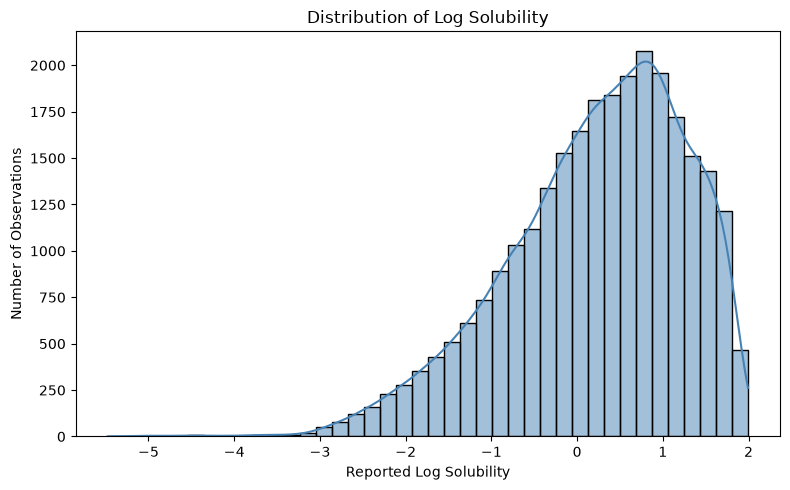

In [61]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="value",
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Log Solubility")
plt.xlabel("Reported Log Solubility")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [62]:
# inspect whether each row contains valid information about the drug and solvent mixture

import ast

# 1. Convert the original CSV text into Python lists
solvent_ids = df["cmp_ids_solvent"].apply(ast.literal_eval)

solvent_fractions = df["cmp_mole_fractions_solvent"].apply(
    ast.literal_eval
)

# 2. Count the items in each list
id_counts = solvent_ids.apply(len)
fraction_counts = solvent_fractions.apply(len)

# 3. Compare the counts
mismatch = id_counts != fraction_counts

# 4. Count and display affected rows
print(
    "Rows with different list lengths:",
    np.count_nonzero(mismatch)
)

print(
    df.loc[
        mismatch,
        ["cmp_ids_solvent", "cmp_mole_fractions_solvent"]
    ].head(10)
)

Rows with different list lengths: 453
     cmp_ids_solvent cmp_mole_fractions_solvent
3815  [127.0, 129.0]                      [1.0]
3816  [127.0, 129.0]                      [1.0]
3817  [127.0, 129.0]                      [1.0]
3818  [127.0, 129.0]                      [1.0]
3819  [127.0, 129.0]                      [1.0]
3820  [127.0, 129.0]                      [1.0]
3821  [127.0, 129.0]                      [1.0]
3822  [127.0, 129.0]                      [1.0]
3823  [127.0, 129.0]                      [1.0]
3824  [127.0, 129.0]                      [1.0]


In [63]:
# find the correct pairing

raw = pd.read_csv(RAW_DIR / "DrugSolubilityData.csv")
print("Raw rows:", len(raw))
print("Processed rows:", len(df))

assert len(raw) == len(df), "Row counts differ"

assert (
    raw["LogS"].to_numpy() == df["value"].to_numpy()
).all(), "Measurement values differ"

assert (
    raw["Temperature, K"].to_numpy()
    == df["Temperature, K"].to_numpy()
).all(), "Temperatures differ"

print("Initial alignment checks passed")

Raw rows: 27166
Processed rows: 27166
Initial alignment checks passed


In [64]:
print("Processed record:")
print(
    df.iloc[3815][
        ["cmp_ids_solvent", "cmp_mole_fractions_solvent"]
    ]
)

print("\nRaw record:")
print(
    raw.iloc[3815][
        ["SMILES_1", "comp_1", "SMILES_2", "comp_2"]
    ]
)

Processed record:
cmp_ids_solvent               [127.0, 129.0]
cmp_mole_fractions_solvent             [1.0]
Name: 3815, dtype: object

Raw record:
SMILES_1       OC
comp_1      100.0
SMILES_2        O
comp_2        0.0
Name: 3815, dtype: object


In [65]:
compounds = pd.read_csv(PROCESSED_DIR / "compounds.csv")
print(compounds[["compound_id", "smiles"]].head())

solvent_matches = compounds["smiles"].str.strip().isin(["OC", "O"])

print(
    compounds.loc[
        solvent_matches,
        ["compound_id", "smiles"]
    ]
)

affected_compositions = raw.loc[
    mismatch,
    ["comp_1", "comp_2"]
]

print("\nAffected compositions:")
print(affected_compositions.value_counts(dropna=False))

   compound_id                                             smiles
0            0                                         Cl.N=C(N)N
1            1                           Cl.O=CC(N)C(O)C(O)C(O)CO
2            2                                   ClC=1N=C(N)C=NC1
3            3     O=N(=O)[O-].OCCC=1SC=[N+](C1C)CC2=CN=C(N=C2N)C
4            4  O=C1NC2=CC(OCCCCN3CCN(C=4C=CC=C(Cl)C4Cl)CC3)=C...
     compound_id smiles
127          127     OC
129          129      O

Affected compositions:
comp_1  comp_2
100.0   0.0       433
0.0     100.0      20
Name: count, dtype: int64


In [66]:
assert raw.index.equals(df.index), "Raw and processed indices differ"

# Identify pure-solvent observations in the processed dataset
processed_fractions = df[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

pure_solvent_mask = processed_fractions.apply(
    lambda fractions: (
        sum(fraction > 0 for fraction in fractions) == 1
        and np.isclose(sum(fractions), 1.0, rtol=0, atol=1e-6)
    )
)

# Check for missing or blank identifiers in either solvent column
def is_missing_identifier(column):
    return (
        column.isna()
        | column.astype("string").str.strip().eq("").fillna(False)
    )

missing_first = is_missing_identifier(raw["SMILES_1"])
missing_second = is_missing_identifier(raw["SMILES_2"])

# Keep pure-solvent rows with at least one missing identifier
matching_mask = (
    pure_solvent_mask
    & (missing_first | missing_second)
)

raw_pure_missing_solvent = raw.loc[
    matching_mask,
    [
        "SMILES_0",
        "SMILES_1", "comp_1",
        "SMILES_2", "comp_2",
        "Temperature, K", "LogS"
    ]
].copy()

# Show which identifier is missing
raw_pure_missing_solvent["missing_SMILES_1"] = missing_first.loc[
    matching_mask
]

raw_pure_missing_solvent["missing_SMILES_2"] = missing_second.loc[
    matching_mask
]

# Include the processed representation for comparison
raw_pure_missing_solvent["processed_solvent_ids"] = df.loc[
    matching_mask, "cmp_ids_solvent"
]

raw_pure_missing_solvent["processed_solvent_fractions"] = df.loc[
    matching_mask, "cmp_mole_fractions_solvent"
]

raw_pure_missing_solvent.index.name = "original_row_index"

# Report mutually exclusive counts
print("Total pure-solvent rows:", int(pure_solvent_mask.sum()))

print(
    "Missing only SMILES_1:",
    int((pure_solvent_mask & missing_first & ~missing_second).sum())
)

print(
    "Missing only SMILES_2:",
    int((pure_solvent_mask & ~missing_first & missing_second).sum())
)

print(
    "Missing both identifiers:",
    int((pure_solvent_mask & missing_first & missing_second).sum())
)

print("Total matching rows:", len(raw_pure_missing_solvent))

display(raw_pure_missing_solvent)

Total pure-solvent rows: 2943
Missing only SMILES_1: 1041
Missing only SMILES_2: 1449
Missing both identifiers: 0
Total matching rows: 2490


,SMILES_0,SMILES_1,comp_1,SMILES_2,comp_2,"Temperature, K",LogS,missing_SMILES_1,missing_SMILES_2,processed_solvent_ids,processed_solvent_fractions
original_row_index,,,,,,,,,,,
15318,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,278.15,0.8951,False,True,[127.0],[1.0]
15319,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,283.15,0.9843,False,True,[127.0],[1.0]
15320,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,288.15,1.0553,False,True,[127.0],[1.0]
15321,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,293.15,1.1281,False,True,[127.0],[1.0]
15322,Cl.N1=C(NCC1)CC2=CC=CC=3C=CC=CC32,OC,100.0,NaN,0.0,298.15,1.2057,False,True,[127.0],[1.0]
...,...,...,...,...,...,...,...,...,...,...,...
27161,O=C(OC)NC1=NC=2C=CC=CC2N1,OCCC,100.0,NaN,0.0,298.15,-2.2307,False,True,[131.0],[1.0]
27162,O=C(OC)NC1=NC=2C=CC=CC2N1,OCCC,100.0,NaN,0.0,303.15,-2.0617,False,True,[131.0],[1.0]
27163,O=C(OC)NC1=NC=2C=CC=CC2N1,OCCC,100.0,NaN,0.0,308.15,-1.8914,False,True,[131.0],[1.0]


In [67]:
smiles = compounds["smiles"].str.strip()

assert not smiles.duplicated().any()
assert not compounds["compound_id"].duplicated().any()

smiles_to_id = dict(zip(smiles, compounds["compound_id"]))

solvent_ids = df["cmp_ids_solvent"].apply(ast.literal_eval)

solvent_fractions = df[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

# Identify length mismatches and existing single-solvent rows
mismatch = (
    solvent_ids.apply(len) != solvent_fractions.apply(len)
)

single_solvent_mask = (
    solvent_ids.apply(len).eq(1)
    & solvent_fractions.apply(len).eq(1)
)

repair_mask = mismatch | single_solvent_mask

def get_raw_solvent_pair(idx):
    """Recover both solvent slots in their original raw-data order."""
    ids = []
    fractions = []

    for position in (1, 2):

        raw_smiles = raw.at[idx, f"SMILES_{position}"]
        raw_percent = raw.at[idx, f"comp_{position}"]

        missing_identifier = (
            pd.isna(raw_smiles)
            or (
                isinstance(raw_smiles, str)
                and not raw_smiles.strip()
            )
        )

        if missing_identifier:

            # Only an absent, zero-fraction solvent may receive "N/A".
            assert pd.isna(raw_percent) or float(raw_percent) == 0.0, (
                f"Missing solvent identifier with nonzero composition "
                f"at row {idx}, position {position}"
            )

            ids.append("N/A")
            fractions.append(0.0)

        else:

            assert isinstance(raw_smiles, str), (
                f"Unexpected solvent identifier at row {idx}"
            )

            assert pd.notna(raw_percent), (
                f"Missing composition for a named solvent at row {idx}"
            )

            solvent_smiles = raw_smiles.strip()

            assert solvent_smiles in smiles_to_id, (
                f"Unknown solvent SMILES at row {idx}: {solvent_smiles}"
            )

            ids.append(int(smiles_to_id[solvent_smiles]))
            fractions.append(float(raw_percent) / 100.0)

    return ids, fractions


repaired = df.copy()

for idx in df.index[repair_mask]:

    raw_ids, fractions = get_raw_solvent_pair(idx)

    assert fractions in ([1.0, 0.0], [0.0, 1.0]), (
        f"Unexpected raw composition at row {idx}: {fractions}"
    )

    assert solvent_fractions.at[idx] == [1.0], (
        f"Unexpected original fraction list at row {idx}"
    )

    if mismatch.at[idx]:

        assert solvent_ids.at[idx] == raw_ids, (
            f"Solvent IDs disagree with raw data at row {idx}"
        )

    else:

        active_id = raw_ids[fractions.index(1.0)]

        assert solvent_ids.at[idx] == [active_id], (
            f"Pure-solvent ID disagrees with raw data at row {idx}"
        )

    # Save both slots in the raw-data order.
    repaired.at[idx, "cmp_ids_solvent"] = str(raw_ids)

    repaired.at[
        idx, "cmp_mole_fractions_solvent"
    ] = str(fractions)


print("Length mismatches repaired:", int(mismatch.sum()))
print("Single-solvent rows expanded:", int(single_solvent_mask.sum()))
print("Total rows updated:", int(repair_mask.sum()))
print("Rows retained:", len(repaired))

Length mismatches repaired: 453
Single-solvent rows expanded: 2490
Total rows updated: 2943
Rows retained: 27166


In [68]:
# Verify the repaired solvent IDs and fractions
repaired_ids = repaired["cmp_ids_solvent"].apply(ast.literal_eval)

repaired_fractions = repaired[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

# Check if all rows contain two solvent slots and two fractions
assert repaired_ids.apply(len).eq(2).all(), (
    "Some rows do not contain two solvent slots"
)

assert repaired_fractions.apply(len).eq(2).all(), (
    "Some rows do not contain two solvent fractions"
)

In [69]:
# Validate IDs, fractions, and N/A positions
known_ids = set(compounds["compound_id"])

for idx in repaired.index:

    ids = repaired_ids.at[idx]
    fractions = repaired_fractions.at[idx]

    assert all(
        isinstance(f, (int, float))
        and not isinstance(f, bool)
        and np.isfinite(f)
        and 0 <= f <= 1
        for f in fractions
    ), f"Invalid fractions at row {idx}"

    assert np.isclose(
        sum(fractions), 1.0, rtol=0, atol=1e-6
    ), f"Fractions do not sum to 1 at row {idx}"

    actual_ids = [cid for cid in ids if cid != "N/A"]

    assert len(actual_ids) == len(set(actual_ids)), (
        f"Repeated solvent ID at row {idx}"
    )

    for cid, fraction in zip(ids, fractions):

        if cid == "N/A":
            assert fraction == 0.0, (
                f"N/A has a nonzero fraction at row {idx}"
            )

        else:
            assert (
                isinstance(cid, (int, float))
                and not isinstance(cid, bool)
                and np.isfinite(cid)
                and cid == int(cid)
                and cid in known_ids
            ), f"Invalid solvent ID at row {idx}: {cid}"

In [70]:
# verify every updated row against the raw data
for idx in repaired.index[repair_mask]:

    ids = repaired_ids.at[idx]
    fractions = repaired_fractions.at[idx]

    for slot, position in enumerate((1, 2)):

        raw_smiles = raw.at[idx, f"SMILES_{position}"]
        raw_percent = raw.at[idx, f"comp_{position}"]

        missing_identifier = (
            pd.isna(raw_smiles)
            or (
                isinstance(raw_smiles, str)
                and not raw_smiles.strip()
            )
        )

        if missing_identifier:

            assert ids[slot] == "N/A", (
                f"Expected N/A at row {idx}, solvent {position}"
            )

            assert fractions[slot] == 0.0, (
                f"Expected zero fraction at row {idx}, solvent {position}"
            )

            assert pd.isna(raw_percent) or float(raw_percent) == 0.0, (
                f"Raw composition contradicts N/A at row {idx}"
            )

        else:

            expected_id = int(smiles_to_id[raw_smiles.strip()])

            assert ids[slot] == expected_id, (
                f"ID or position disagrees with raw data at row {idx}, "
                f"solvent {position}"
            )

            assert pd.notna(raw_percent), (
                f"Missing raw composition at row {idx}, solvent {position}"
            )

            assert np.isclose(
                fractions[slot],
                float(raw_percent) / 100.0,
                rtol=0,
                atol=1e-12
            ), (
                f"Fraction disagrees with raw data at row {idx}, "
                f"solvent {position}"
            )

In [71]:
# verify that only the intended rows and columns changed

assert repaired.index.equals(df.index)

original_ids = df["cmp_ids_solvent"].apply(ast.literal_eval)
updated_ids = repaired["cmp_ids_solvent"].apply(ast.literal_eval)

original_fractions = df[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

updated_fractions = repaired[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

# Numeric IDs such as 127 and 127.0 compare as equal
changed_ids = pd.Series(
    [
        before != after
        for before, after in zip(original_ids, updated_ids)
    ],
    index=df.index
)

changed_fractions = pd.Series(
    [
        before != after
        for before, after in zip(original_fractions, updated_fractions)
    ],
    index=df.index
)

# Only the original single-solvent rows should gain an ID slot

assert changed_ids.eq(single_solvent_mask).all(), (
    "Unexpected changes to solvent ID contents"
)

# Both mismatched and single-solvent rows should gain a fraction slot

assert changed_fractions.eq(repair_mask).all(), (
    "Unexpected changes to solvent fraction contents"
)

print("Rows with changed ID contents:", int(changed_ids.sum()))
print("Rows with changed fraction contents:", int(changed_fractions.sum()))
solvent_columns = [
    "cmp_ids_solvent",
    "cmp_mole_fractions_solvent"
]

assert repaired.drop(columns=solvent_columns).equals(
    df.drop(columns=solvent_columns)
), "An unrelated column changed"

assert repaired.loc[~repair_mask].equals(
    df.loc[~repair_mask]
), "A row outside the repair mask changed"

# confirm no rows were removed or reordered

assert len(repaired) == len(df)
assert repaired.index.equals(df.index)

# report the verified results

missing_first_count = updated_ids.apply(
    lambda ids: ids[0] == "N/A"
).sum()

missing_second_count = updated_ids.apply(
    lambda ids: ids[1] == "N/A"
).sum()

print("Length mismatches repaired:", int(mismatch.sum()))
print("Single-solvent rows expanded:", int(single_solvent_mask.sum()))
print("N/A in first solvent slot:", int(missing_first_count))
print("N/A in second solvent slot:", int(missing_second_count))
print("Rows retained:", len(repaired))
print("All repair verification checks passed.")

Rows with changed ID contents: 2490
Rows with changed fraction contents: 2943
Length mismatches repaired: 453
Single-solvent rows expanded: 2490
N/A in first solvent slot: 1041
N/A in second solvent slot: 1449
Rows retained: 27166
All repair verification checks passed.


In [72]:
# check the duplication after repair

def active_composition(ids_text, fractions_text):
    ids = ast.literal_eval(ids_text)
    fractions = ast.literal_eval(fractions_text)

    assert len(ids) == len(fractions)

    # Ignore zero-fraction slots before converting IDs to integers.
    # This also excludes "N/A", whose fraction was verified as zero.
    return tuple(sorted(
        (int(cid), float(fraction))
        for cid, fraction in zip(ids, fractions)
        if fraction > 0
    ))


# Preserve all other fields in the duplicate comparison,

composition_columns = [
    "cmp_ids_drug",
    "cmp_mole_fractions_drug",
    "cmp_ids_solvent",
    "cmp_mole_fractions_solvent"
]

duplicate_keys = repaired.drop(columns=composition_columns).copy()

for kind in ["drug", "solvent"]:
    duplicate_keys[f"active_{kind}_composition"] = [
        active_composition(ids, fractions)
        for ids, fractions in zip(
            repaired[f"cmp_ids_{kind}"],
            repaired[f"cmp_mole_fractions_{kind}"]
        )
    ]

duplicate_mask = duplicate_keys.duplicated(keep="first")

duplicate_rows = repaired.loc[
    duplicate_keys.duplicated(keep=False)
]

print("Exact text-based duplicates:", int(repaired.duplicated().sum()))
print("Duplicate rows to remove:", int(duplicate_mask.sum()))

display(duplicate_rows)

Exact text-based duplicates: 0
Duplicate rows to remove: 9


,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug
7905,0.8258,278.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7906,0.8851,283.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7907,0.9437,288.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7908,1.0033,293.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7909,1.0609,298.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7910,1.1096,303.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7911,1.1606,308.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7912,1.2084,313.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7913,1.2571,318.15,Log solubility,g/L,"[145, 130]","[1.0, 0.0]",[36],[1.0]
7995,0.8258,278.15,Log solubility,g/L,"[145, 140]","[1.0, 0.0]",[36],[1.0]


In [73]:
# for duplications, keeping the first occurrence

removed_duplicates = repaired.loc[duplicate_mask].copy()
cleaned = repaired.loc[~duplicate_mask].copy()

# Verify removal using the same comparison keys
assert not duplicate_keys.loc[cleaned.index].duplicated().any()
assert len(cleaned) + len(removed_duplicates) == len(repaired)

print("Rows before duplicate removal:", len(repaired))
print("Duplicate rows removed:", len(removed_duplicates))
print("Rows after duplicate removal:", len(cleaned))

Rows before duplicate removal: 27166
Duplicate rows removed: 9
Rows after duplicate removal: 27157


In [74]:
# inspect whether each row contains valid information after cleaning

values = cleaned["value"]
temperatures = cleaned["Temperature, K"]

# Flag invalid measurements
invalid_value = ~np.isfinite(values)

# Flag invalid temperatures
invalid_temperature = (
    ~np.isfinite(temperatures)
    | (temperatures <= 0)
)

print("Invalid measurement values:", invalid_value.sum())
print("Invalid temperatures:", invalid_temperature.sum())

invalid_numeric = invalid_value | invalid_temperature

print(
    cleaned.loc[
        invalid_numeric,
        ["value", "Temperature, K"]
    ].head(10)
)

Invalid measurement values: 0
Invalid temperatures: 0
Empty DataFrame
Columns: [value, Temperature, K]
Index: []


In [75]:
#check if ids and solvent are valid

known_ids = set(compounds["compound_id"])


def valid_ids(items, allow_missing=False):
    if not isinstance(items, list) or len(items) == 0:
        return False

    actual_ids = []

    for item in items:

        if item == "N/A":
            if not allow_missing:
                return False
            continue

        if isinstance(item, bool) or not isinstance(item, (int, float)):
            return False

        if not np.isfinite(item):
            return False

        if item < 0 or item != int(item) or item not in known_ids:
            return False

        actual_ids.append(int(item))

    # Require at least one real compound and no repeated real IDs
    return (
        len(actual_ids) > 0
        and len(actual_ids) == len(set(actual_ids))
    )


def valid_fractions(items):
    if not isinstance(items, list) or len(items) == 0:
        return False

    for item in items:

        if isinstance(item, bool) or not isinstance(item, (int, float)):
            return False

        if not np.isfinite(item) or not 0 <= item <= 1:
            return False

    return np.isclose(
        sum(items),
        1.0,
        rtol=0,
        atol=1e-6
    )


for kind in ["drug", "solvent"]:

    ids = cleaned[f"cmp_ids_{kind}"].apply(ast.literal_eval)

    fractions = cleaned[
        f"cmp_mole_fractions_{kind}"
    ].apply(ast.literal_eval)

    # N/A is allowed only in solvent lists
    bad_ids = ~ids.apply(
        lambda items: valid_ids(
            items,
            allow_missing=(kind == "solvent")
        )
    )

    bad_fractions = ~fractions.apply(valid_fractions)

    bad_lengths = ids.apply(len) != fractions.apply(len)

    # This dataset should have one drug slot and two solvent slots
    expected_slots = 2 if kind == "solvent" else 1

    bad_slot_counts = (
        ids.apply(len).ne(expected_slots)
        | fractions.apply(len).ne(expected_slots)
    )

    # Any N/A must be a solvent slot paired with exactly zero
    bad_na_pairs = pd.Series(
        [
            any(
                cid == "N/A"
                and (kind != "solvent" or fraction != 0.0)
                for cid, fraction in zip(id_list, fraction_list)
            )
            for id_list, fraction_list in zip(ids, fractions)
        ],
        index=cleaned.index
    )

    print(f"\n{kind.upper()}")
    print("Invalid ID lists:", int(bad_ids.sum()))
    print("Invalid fraction lists:", int(bad_fractions.sum()))
    print("Length mismatches:", int(bad_lengths.sum()))
    print("Incorrect number of slots:", int(bad_slot_counts.sum()))
    print("Invalid N/A–fraction pairs:", int(bad_na_pairs.sum()))

    bad_rows = (
        bad_ids
        | bad_fractions
        | bad_lengths
        | bad_slot_counts
        | bad_na_pairs
    )

    if bad_rows.any():
        display(
            cleaned.loc[
                bad_rows,
                [f"cmp_ids_{kind}", f"cmp_mole_fractions_{kind}"]
            ].head(10)
        )

    assert not bad_rows.any(), (
        f"Review the invalid {kind} compositions shown above"
    )

print("\nAll ID and fraction validation checks passed.")


DRUG
Invalid ID lists: 0
Invalid fraction lists: 0
Length mismatches: 0
Incorrect number of slots: 0
Invalid N/A–fraction pairs: 0

SOLVENT
Invalid ID lists: 0
Invalid fraction lists: 0
Length mismatches: 0
Incorrect number of slots: 0
Invalid N/A–fraction pairs: 0

All ID and fraction validation checks passed.


In [76]:
# check if ID–fraction pairs in the cleaned data match the original raw data

def pairs_match(actual, expected):

    # Support both numeric IDs and the "N/A" placeholder.
    # Sort complete ID–fraction pairs so each fraction stays with its ID.
    sort_key = lambda pair: (
        pair[0] == "N/A",
        str(pair[0])
    )

    actual = sorted(actual, key=sort_key)
    expected = sorted(expected, key=sort_key)

    if len(actual) != len(expected):
        return False

    for (id_a, fraction_a), (id_b, fraction_b) in zip(actual, expected):

        if id_a != id_b:
            return False

        if not np.isclose(
            fraction_a,
            fraction_b,
            rtol=0,
            atol=1e-12
        ):
            return False

    return True


# Original indices must still identify the corresponding raw rows
assert cleaned.index.is_unique
assert cleaned.index.isin(raw.index).all()

pair_issues = []
numeric_issues = []

for idx, row in cleaned.iterrows():

    source = raw.loc[idx]

    # Verify measurement and temperature against the raw row
    for processed_column, raw_column in [
        ("value", "LogS"),
        ("Temperature, K", "Temperature, K")
    ]:
        if not np.isclose(
            row[processed_column],
            source[raw_column],
            rtol=0,
            atol=1e-12
        ):
            numeric_issues.append((idx, processed_column))

    # Verify drug and solvent compositions
    for kind in ["drug", "solvent"]:

        ids = ast.literal_eval(row[f"cmp_ids_{kind}"])

        fractions = ast.literal_eval(
            row[f"cmp_mole_fractions_{kind}"]
        )

        if len(ids) != len(fractions):
            pair_issues.append((idx, kind, "List length mismatch"))
            continue

        # Keep ALL entries, including zero fractions and N/A
        actual = [
            (
                "N/A" if cid == "N/A" else int(cid),
                float(fraction)
            )
            for cid, fraction in zip(ids, fractions)
        ]

        if kind == "solvent":

            # Use the helper defined in the repair cell
            expected_ids, expected_fractions = get_raw_solvent_pair(idx)

            expected = list(zip(
                expected_ids,
                expected_fractions
            ))

        else:

            drug_smiles = source["SMILES_0"].strip()

            expected = [
                (
                    int(smiles_to_id[drug_smiles]),
                    float(source["comp_0"]) / 100.0
                )
            ]

        if not pairs_match(actual, expected):
            pair_issues.append((idx, kind, "ID–fraction mismatch"))


print("Raw/cleaned composition mismatches:", len(pair_issues))
print("Raw/cleaned numeric mismatches:", len(numeric_issues))

print("First composition issues:", pair_issues[:10])
print("First numeric issues:", numeric_issues[:10])

assert not pair_issues, "Review the composition mismatches"
assert not numeric_issues, "Review the numeric mismatches"

print("All cleaned rows match their corresponding raw observations.")

Raw/cleaned composition mismatches: 0
Raw/cleaned numeric mismatches: 0
First composition issues: []
First numeric issues: []
All cleaned rows match their corresponding raw observations.


In [77]:
# Keep ALL drugs, including pure solvents and binary mixtures

subset = cleaned.copy()

solvent_fraction_lists = subset[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

active_solvent_counts = solvent_fraction_lists.apply(
    lambda fractions: sum(fraction > 0 for fraction in fractions)
)

pure_solvent_mask = active_solvent_counts.eq(1)
binary_mask = active_solvent_counts.eq(2)

assert active_solvent_counts.isin([1, 2]).all()
assert len(subset) == len(cleaned)

print("Total observations:", len(subset))
print("Pure-solvent observations:", int(pure_solvent_mask.sum()))
print("Binary-mixture observations:", int(binary_mask.sum()))

drug_lists = subset["cmp_ids_drug"].apply(ast.literal_eval)

assert drug_lists.apply(len).eq(1).all(), (
    "Review observations containing more than one drug"
)

subset_drug_ids = drug_lists.apply(lambda ids: int(ids[0]))

drug_names = {
    int(cid): f"Drug {int(cid)}"
    for cid in subset_drug_ids.unique()
}

drug_names.update({
    5: "Itraconazole",
    43: "Posaconazole",
    86: "Ketoconazole"
})

counts = (
    subset_drug_ids.value_counts()
    .sort_index()
    .rename(index=drug_names)
)

print("\nNumber of drugs:", subset_drug_ids.nunique())
print("\nObservations per drug:")
print(counts)

assert counts.sum() == len(subset)

# Prepare the dataframe for outlier-analysis

review = subset.copy()

review["drug_id"] = subset_drug_ids
review["drug"] = subset_drug_ids.map(drug_names)

review["solvent_type"] = np.where(
    pure_solvent_mask,
    "pure",
    "binary"
)

# Create a grouping label from the recorded solvent IDs.
# Exclude N/A from the label, but retain any recorded zero-percent solvent.

def get_solvent_pair(text):
    ids = ast.literal_eval(text)

    return tuple(sorted(
        int(cid)
        for cid in ids
        if cid != "N/A"
    ))

review["solvent_pair"] = review["cmp_ids_solvent"].apply(
    get_solvent_pair
)

assert review["drug"].notna().all()

print("\nRecorded solvent systems per drug:")
print(review.groupby("drug")["solvent_pair"].nunique())

Total observations: 27157
Pure-solvent observations: 2934
Binary-mixture observations: 24223

Number of drugs: 125

Observations per drug:
cmp_ids_drug
Drug 0      200
Drug 1      116
Drug 2      306
Drug 3      184
Drug 4      279
           ... 
Drug 120    144
Drug 121    168
Drug 122    369
Drug 123    369
Drug 124     72
Name: count, Length: 125, dtype: int64

Recorded solvent systems per drug:
drug
Drug 0           4
Drug 1           4
Drug 10          2
Drug 100         4
Drug 101         3
                ..
Drug 98          3
Drug 99          3
Itraconazole    14
Ketoconazole     5
Posaconazole     4
Name: solvent_pair, Length: 125, dtype: int64


In [78]:
# identifying the outliers using IQR method

iqr_review = review.copy()

iqr_review["LogS_iqr_flag"] = False
iqr_review["Temperature_iqr_flag"] = False

results = []

# Group by BOTH drug and solvent pair
for (drug, pair), group in iqr_review.groupby(
    ["drug", "solvent_pair"]
):
    # Screen each numerical variable separately
    for column, label in [
        ("value", "LogS"),
        ("Temperature, K", "Temperature")
    ]:
        values = group[column]

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        flags = (values < lower) | (values > upper)

        iqr_review.loc[group.index, f"{label}_iqr_flag"] = flags

        results.append({
            "Drug": drug,
            "Solvent pair": pair,
            "Variable": label,
            "Observations": len(values),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower limit": lower,
            "Upper limit": upper,
            "Flagged": int(flags.sum())
        })

summary = pd.DataFrame(results)

print(summary.to_string(index=False))


flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]

any_flag = iqr_review[flag_columns].any(axis=1)

print("\nFlags per variable:")
print(iqr_review[flag_columns].sum())

print("\nUnique flagged observations:", any_flag.sum())

print(
    iqr_review.loc[
        any_flag,
        [
            "drug",
            "solvent_pair",
            "solvent_type",
            "value",
            "Temperature, K",
            "LogS_iqr_flag",
            "Temperature_iqr_flag"
        ]
    ].to_string()
)

        Drug Solvent pair    Variable  Observations         Q1         Q3       IQR  Lower limit  Upper limit  Flagged
      Drug 0   (125, 131)        LogS            50   1.351575   1.636100  0.284525     0.924787     2.062888        0
      Drug 0   (125, 131) Temperature            50 288.150000 313.150000 25.000000   250.650000   350.650000        0
      Drug 0   (126, 131)        LogS            50   1.309475   1.521750  0.212275     0.991062     1.840162        0
      Drug 0   (126, 131) Temperature            50 288.150000 313.150000 25.000000   250.650000   350.650000        0
      Drug 0   (127, 131)        LogS            50   1.279925   1.557250  0.277325     0.863937     1.973238        0
      Drug 0   (127, 131) Temperature            50 288.150000 313.150000 25.000000   250.650000   350.650000        0
      Drug 0   (128, 131)        LogS            50   1.272950   1.633200  0.360250     0.732575     2.173575        0
      Drug 0   (128, 131) Temperature           

In [79]:
# Summarize IQR flags without printing every group

flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]

flagged_mask = iqr_review[flag_columns].any(axis=1)
flagged_rows = iqr_review.loc[flagged_mask].copy()

print("Total observations:", len(iqr_review))
print("LogS flags:", int(iqr_review["LogS_iqr_flag"].sum()))
print("Temperature flags:", int(iqr_review["Temperature_iqr_flag"].sum()))
print("Unique flagged observations:", len(flagged_rows))
print(f"Percentage flagged: {100 * flagged_mask.mean():.2f}%")

print("\nFlagged observations by solvent type:")
print(flagged_rows["solvent_type"].value_counts().to_string())

# Show only group-variable combinations with at least one flag
flagged_groups = summary.loc[summary["Flagged"] > 0]

print("\nGroup-variable combinations with flags:", len(flagged_groups))
display(flagged_groups.head(20))

# Preserve the complete results for inspection
summary.to_csv("iqr_summary_all_drugs.csv", index=False)

flagged_rows.to_csv(
    "iqr_flagged_rows_all_drugs.csv",
    index=True,
    index_label="original_row_index"
)

Total observations: 27157
LogS flags: 311
Temperature flags: 0
Unique flagged observations: 311
Percentage flagged: 1.15%

Flagged observations by solvent type:
solvent_type
binary    306
pure        5

Group-variable combinations with flags: 121


,Drug,Solvent pair,Variable,Observations,Q1,Q3,IQR,Lower limit,Upper limit,Flagged
24,Drug 100,"(130, 137)",LogS,45,-0.450500,0.300800,0.751300,-1.577450,1.427750,1
36,Drug 102,"(133, 140)",LogS,81,-0.078000,0.374600,0.452600,-0.756900,1.053500,1
44,Drug 102,"(140, 159)",LogS,81,-0.228400,0.104500,0.332900,-0.727750,0.603850,2
54,Drug 103,"(129, 130)",LogS,28,1.454775,1.665575,0.210800,1.138575,1.981775,3
120,Drug 109,"(127, 132)",LogS,9,1.110300,1.153800,0.043500,1.045050,1.219050,1
122,Drug 109,"(127, 144)",LogS,9,1.049300,1.236200,0.186900,0.768950,1.516550,1
132,Drug 109,"(130, 144)",LogS,9,1.066900,1.285900,0.219000,0.738400,1.614400,1
136,Drug 109,"(132, 144)",LogS,9,0.820800,1.041500,0.220700,0.489750,1.372550,1
140,Drug 11,"(129, 141)",LogS,81,0.493200,0.730500,0.237300,0.137250,1.086450,1
142,Drug 11,"(129, 142)",LogS,81,0.675400,0.875000,0.199600,0.376000,1.174400,6


In [80]:
# deciding whether to remove or retain the outlier

import matplotlib.pyplot as plt

plot_review = iqr_review.copy()

flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]

plot_review["any_iqr_flag"] = plot_review[flag_columns].any(axis=1)


def get_active_solvent_ids(row):
    ids = ast.literal_eval(row["cmp_ids_solvent"])
    fractions = ast.literal_eval(row["cmp_mole_fractions_solvent"])

    return tuple(sorted(
        int(cid)
        for cid, fraction in zip(ids, fractions)
        if fraction > 0
    ))


def get_first_solvent_fraction(row):
    ids = ast.literal_eval(row["cmp_ids_solvent"])
    fractions = ast.literal_eval(row["cmp_mole_fractions_solvent"])

    fraction_by_id = dict(zip(ids, fractions))

    # solvent_pair contains only recorded numeric IDs, excluding N/A
    first_id = row["solvent_pair"][0]

    return fraction_by_id[first_id]


plot_review["active_solvent_ids"] = plot_review.apply(
    get_active_solvent_ids,
    axis=1
)

plot_review["x_first"] = plot_review.apply(
    get_first_solvent_fraction,
    axis=1
)

# List every drug–solvent group containing flagged observations
review_queue = (
    plot_review.loc[plot_review["any_iqr_flag"]]
    .groupby(["drug", "solvent_pair"])
    .size()
    .reset_index(name="flagged_count")
)

review_queue.index.name = "group_number"

print("Number of flagged groups:", len(review_queue))
display(review_queue)


def plot_flagged_group(group_number):
    """Inspect one group using its number in review_queue."""

    if not 0 <= group_number < len(review_queue):
        raise ValueError(
            f"Choose a group number from 0 to {len(review_queue) - 1}"
        )

    selected = review_queue.iloc[group_number]

    drug = selected["drug"]
    pair = selected["solvent_pair"]

    same_drug = plot_review["drug"].eq(drug)

    fig, ax = plt.subplots(figsize=(10, 6))

    if len(pair) == 1:
        # Include all pure observations of this drug in this actual solvent,
        # even if some were recorded with a named zero-percent partner.
        same_active_solvent = plot_review[
            "active_solvent_ids"
        ].apply(lambda ids: ids == pair)

        plot_data = plot_review.loc[
            same_drug & same_active_solvent
        ].copy()

        plot_data = plot_data.sort_values("Temperature, K")

        x_column = "Temperature, K"

        ax.plot(
            plot_data[x_column],
            plot_data["value"],
            marker="o",
            markersize=4,
            linewidth=1,
            label="Pure-solvent observations"
        )

        ax.set_xlabel("Temperature (K)")
        ax.set_title(f"{drug} — pure solvent ID {pair[0]}")

    else:
        # Include mixtures and any endpoints recorded under this pair.
        same_pair = plot_review["solvent_pair"].apply(
            lambda ids: ids == pair
        )

        plot_data = plot_review.loc[
            same_drug & same_pair
        ].copy()

        x_column = "x_first"

        for temperature, series in plot_data.groupby("Temperature, K"):

            series = series.sort_values(x_column)

            ax.plot(
                series[x_column],
                series["value"],
                marker="o",
                markersize=4,
                linewidth=1,
                label=f"{temperature:g} K"
            )

        ax.set_xlabel(f"Mole fraction of solvent {pair[0]}")
        ax.set_xlim(-0.03, 1.03)
        ax.set_title(f"{drug} — solvent IDs {pair}")

    # Highlight and label every flagged observation shown
    flagged_points = plot_data.loc[
        plot_data["any_iqr_flag"]
    ]

    ax.scatter(
        flagged_points[x_column],
        flagged_points["value"],
        s=130,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5,
        zorder=5,
        label="IQR-flagged observations"
    )

    for idx, row in flagged_points.iterrows():
        ax.annotate(
            str(idx),
            (row[x_column], row["value"]),
            xytext=(5, 6),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_ylabel("Log solubility (recorded value)")
    ax.grid(alpha=0.3)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

    fig.tight_layout()
    plt.show()

    print(f"Review group {group_number}: {drug}, {pair}")
    print("Flagged observations shown:")

    display(
        flagged_points[
            [
                "drug",
                "solvent_pair",
                "solvent_type",
                "value",
                "Temperature, K",
                "cmp_ids_solvent",
                "cmp_mole_fractions_solvent",
                "LogS_iqr_flag",
                "Temperature_iqr_flag"
            ]
        ]
    )

    return fig


Number of flagged groups: 121


,drug,solvent_pair,flagged_count
group_number,,,
0,Drug 100,"(130, 137)",1
1,Drug 102,"(133, 140)",1
2,Drug 102,"(140, 159)",2
3,Drug 103,"(129, 130)",3
4,Drug 109,"(127, 132)",1
...,...,...,...
116,Drug 90,"(125, 129)",1
117,Drug 90,"(142, 145)",1
118,Drug 92,"(134,)",1


In [81]:
# Retain IQR-flagged observations by policy

flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]
flagged_mask = iqr_review[flag_columns].any(axis=1)

outlier_policy_report = iqr_review.loc[flagged_mask].copy()
outlier_policy_report.index.name = "original_row_index"

outlier_policy_report["decision"] = "retain"

outlier_policy_report["review_status"] = (
    "Individual review not documented"
)

outlier_policy_report["reason"] = (
    "Retained under the no-automatic-IQR-exclusion policy. "
    "An IQR flag alone does not establish a data error; "
    "individual validity has not been established."
)

outlier_policy_report["evidence"] = (
    "Dataset passed numeric, composition, and raw-data consistency checks. "
    "These checks do not establish the accuracy of the original measurement."
)

print("Flagged observations:", len(outlier_policy_report))
print("Default decision: retain")

Flagged observations: 311
Default decision: retain


In [82]:
# Only enter errors supported by specific evidence.
# Keys must be original row indices of flagged observations.

confirmed_outlier_errors = {
    # Example structure:
    # ORIGINAL_ROW_INDEX: {
    #     "reason": "Describe the confirmed error and why it cannot be corrected.",
    #     "evidence": "Identify the source or check confirming the error."
    # }
}

unknown_indices = (
    set(confirmed_outlier_errors)
    - set(outlier_policy_report.index)
)

assert not unknown_indices, (
    f"These indices are not flagged observations: {unknown_indices}"
)

for idx, details in confirmed_outlier_errors.items():

    reason = details.get("reason", "")
    evidence = details.get("evidence", "")

    assert isinstance(reason, str) and reason.strip(), (
        f"Provide a reason for removing row {idx}"
    )

    assert isinstance(evidence, str) and evidence.strip(), (
        f"Provide supporting evidence for row {idx}"
    )

    outlier_policy_report.at[idx, "decision"] = "remove"
    outlier_policy_report.at[idx, "review_status"] = "Confirmed error"
    outlier_policy_report.at[idx, "reason"] = reason
    outlier_policy_report.at[idx, "evidence"] = evidence

print("Confirmed errors to remove:", len(confirmed_outlier_errors))

Confirmed errors to remove: 0


In [83]:
# Remove only explicitly documented, confirmed errors

remove_indices = outlier_policy_report.index[
    outlier_policy_report["decision"].eq("remove")
]

final_data = cleaned.drop(index=remove_indices).copy()

# Verify the row count and absence of previously identified duplicates
assert len(final_data) == len(cleaned) - len(remove_indices)
assert not duplicate_keys.loc[final_data.index].duplicated().any()

# Save the original data columns, including all drugs and solvent types
final_data.to_csv(
    "final_cleaned_all_drugs_pure_and_binary.csv",
    index=False
)

# Save flags, policy decisions, review status, reasons, and evidence
outlier_policy_report.to_csv(
    "outlier_policy_report.csv",
    index=True,
    index_label="original_row_index"
)

retained_flags = outlier_policy_report["decision"].eq("retain").sum()

print("Rows before outlier decisions:", len(cleaned))
print("IQR-flagged observations retained:", int(retained_flags))
print("Confirmed erroneous observations removed:", len(remove_indices))
print("Final dataset rows:", len(final_data))
print("\nFinal dataset and outlier policy report saved.")

Rows before outlier decisions: 27157
IQR-flagged observations retained: 311
Confirmed erroneous observations removed: 0
Final dataset rows: 27157

Final dataset and outlier policy report saved.


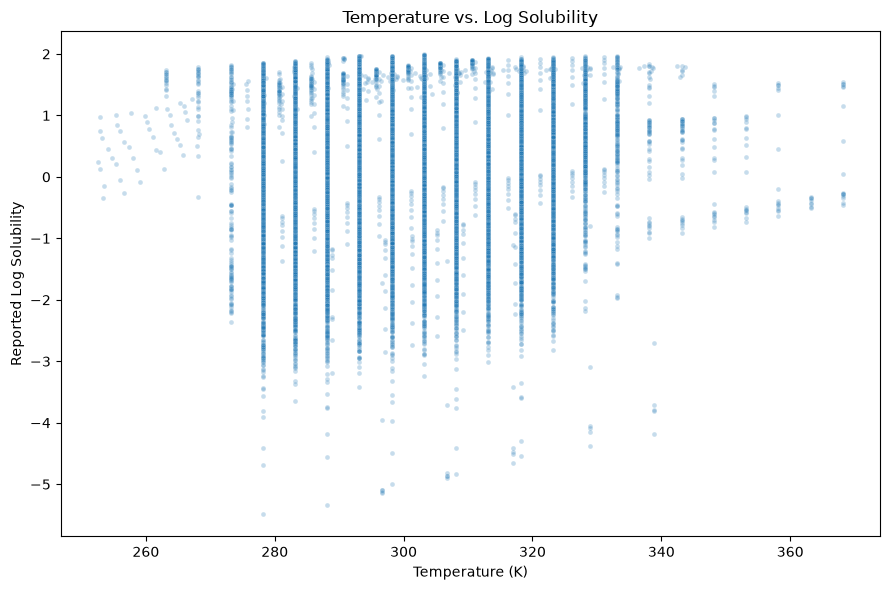

In [84]:
#Plotting correltion between temperature and log solubility
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Temperature, K",
    y="value",
    alpha=0.25,
    s=12
)

plt.title("Temperature vs. Log Solubility")
plt.xlabel("Temperature (K)")
plt.ylabel("Reported Log Solubility")

plt.tight_layout()
plt.savefig("temperature_vs_solubility.png", dpi=300)
plt.show()


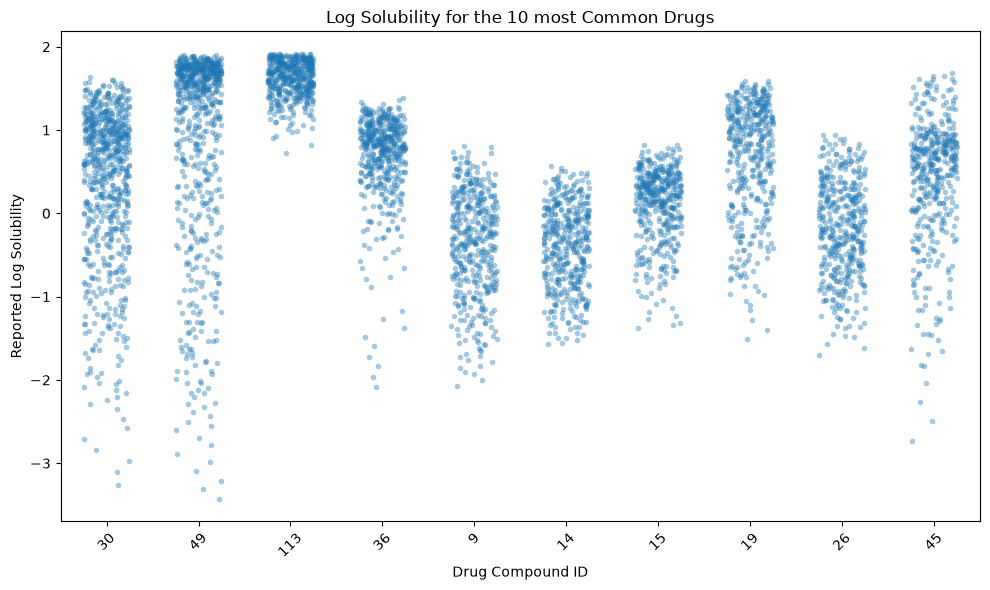

In [85]:
#Correlation between 10 most common drug types and log solubility

#Finding the most common drug types and separating them
def parse_drug_ids(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if isinstance(value, (list, tuple)):
        ids = value
    elif pd.isna(value):
        return []
    else:
        ids = [value]

    # Normalize values such as 115.0 to "115" for display.
    return [
        str(int(float(drug_id)))
        if float(drug_id).is_integer()
        else str(drug_id)
        for drug_id in ids
    ]

plot_df = df.assign(
    drug_id = df["cmp_ids_drug"].apply(parse_drug_ids)
).explode("drug_id")

top_drugs = plot_df["drug_id"].value_counts().head(10).index.tolist()
plot_df = plot_df[plot_df["drug_id"].isin(top_drugs)].copy()
plot_df["drug_id"] = pd.Categorical(
    plot_df["drug_id"], categories=top_drugs, ordered=True
)

#Plotting the correlation
plt.figure(figsize=(10, 6))
sns.stripplot(
    data=plot_df,
    x="drug_id",
    y="value",
    order = top_drugs,
    jitter = 0.25,
    alpha=0.4,
    size=4
)

plt.title("Log Solubility for the 10 most Common Drugs")
plt.xlabel("Drug Compound ID")
plt.ylabel("Reported Log Solubility")
plt.xticks(rotation = 45)

plt.tight_layout()
plt.savefig("drug_vs_logsolubility.png", dpi=300)
plt.show()

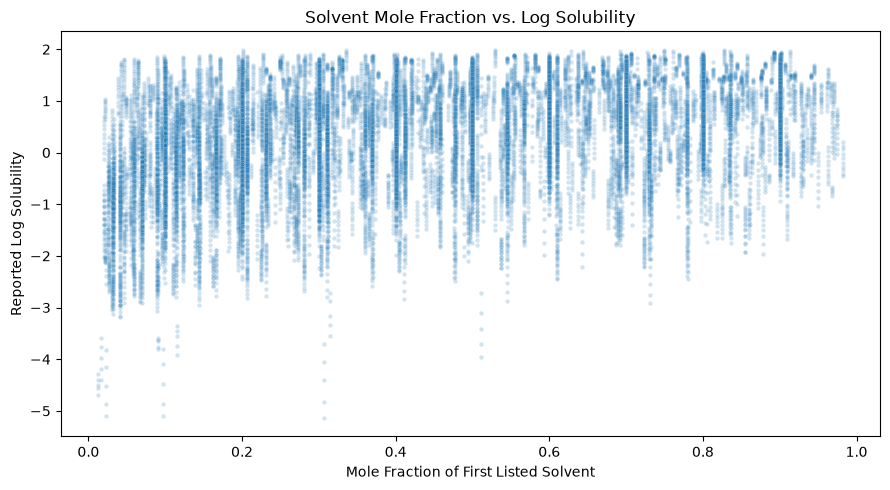

In [86]:
#Correlation between solvent mole fraction and log solubility for binary mixtures

# Extract the solvent mole fractions and identify binary mixtures
solvent_fractions = df["cmp_mole_fractions_solvent"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

df["solvent_type"] = solvent_fractions.apply(
    lambda fractions: "Two solvents"
    if sum(float(f) > 1e-10 for f in fractions) == 2
    else "Single solvent"
)

binary_df = df[df["solvent_type"] == "Two solvents"].copy()
binary_df["solvent_1_fraction"] = (
    solvent_fractions.loc[binary_df.index].apply(lambda x: x[0])
)

#Plotting the correlation
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=binary_df,
    x="solvent_1_fraction",
    y="value",
    alpha=0.2,
    s=10
)

plt.title("Solvent Mole Fraction vs. Log Solubility")
plt.xlabel("Mole Fraction of First Listed Solvent")
plt.ylabel("Reported Log Solubility")

plt.tight_layout()
plt.savefig("solvent_fraction_vs_solubility.png", dpi=300)
plt.show()


Spearman correlation matrix:


,"Temperature, K",solvent_1_fraction,value
"Temperature, K",1.0000,0.0209,0.1946
solvent_1_fraction,0.0209,1.0000,0.3564
value,0.1946,0.3564,1.0000


Correlation matrix:
                    Temperature, K  solvent_1_fraction  value
Temperature, K               1.000               0.023  0.187
solvent_1_fraction           0.023               1.000  0.354
value                        0.187               0.354  1.000


<Figure size 700x500 with 0 Axes>

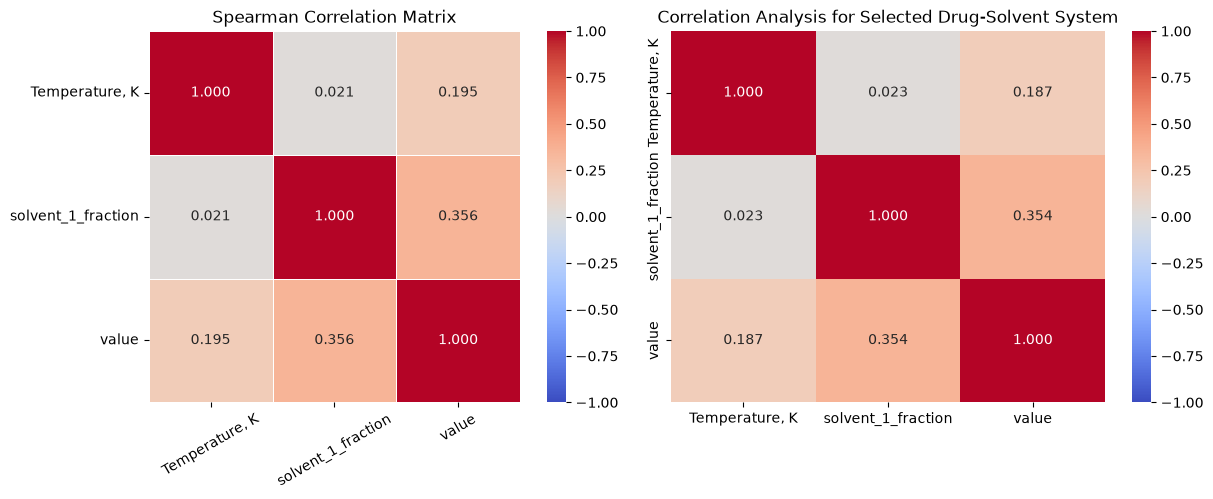

In [87]:
# Correlation analysis for selected drug-solvent system

correlation = binary_df [
    ["Temperature, K", "solvent_1_fraction", "value"]
].corr()

# Spearman measures monotonic association
spearman_corr = binary_df[
    ["Temperature, K", "solvent_1_fraction", "value"]
].corr(method="spearman")

print("\nSpearman correlation matrix:")
display(spearman_corr.round(4))

print("Correlation matrix:")
print(correlation.round(3))

plt.figure(figsize=(7, 5))

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, title in zip(
    axes,
    [spearman_corr, correlation],
    ["Spearman Correlation Matrix"]
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        ax=ax
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)


sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Analysis for Selected Drug-Solvent System")
plt.tight_layout()
plt.savefig("specific_system_correlation.png", dpi=300)
plt.show()


In [88]:
#Define the global variables
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)
LogSolubility = "value"
FeatureColumns = ["Temperature, K", "cmp_mole_fractions_solvent", "cmp_ids_solvent", "cmp_ids_drug"]

#train/test stratification split of the log solubility values
LogSolubility_Binary = "value_binary"
Cutoff = df[LogSolubility].quantile(0.9)
df[LogSolubility_Binary] = (df[LogSolubility] > Cutoff).astype(int)

train_df, test_df = train_test_split(
    df,
    test_size = 0.2,
    train_size = 0.8,
    stratify = df[LogSolubility_Binary],
    random_state = RANDOM_SEED
)

#check splitting is done correctly
train_df.head(5)


,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug,solvent_type,value_binary
22745,0.1670,283.15,Log solubility,g/L,"[139.0, 129.0]","[0.224999, 0.775001]",[115],[1.0],Two solvents,0
7796,1.2549,318.15,Log solubility,g/L,"[144.0, 129.0]","[0.506009, 0.49399099999999996]",[36],[1.0],Two solvents,0
626,0.1669,288.15,Log solubility,g/L,"[129.0, 127.0]","[0.6, 0.4]",[3],[1.0],Two solvents,0
11032,1.1581,283.15,Log solubility,g/L,"[125.0, 129.0]","[0.365186, 0.634814]",[48],[1.0],Two solvents,0
3061,0.2512,303.15,Log solubility,g/L,"[131.0, 129.0]","[0.545362, 0.454638]",[14],[1.0],Two solvents,0


In [89]:
test_df.head(5)

,value,"Temperature, K",property,unit,cmp_ids_solvent,cmp_mole_fractions_solvent,cmp_ids_drug,cmp_mole_fractions_drug,solvent_type,value_binary
11429,1.5459,313.15,Log solubility,g/L,"[144.0, 129.0]","[0.506009, 0.49399099999999996]",[49],[1.0],Two solvents,1
23610,1.2631,273.15,Log solubility,g/L,"[147.0, 144.0]","[0.2, 0.8]",[119],[1.0],Two solvents,0
13844,-0.2767,278.15,Log solubility,g/L,"[130.0, 129.0]","[0.041654, 0.9583459999999999]",[62],[1.0],Two solvents,0
21451,0.2777,313.15,Log solubility,g/L,"[131.0, 129.0]","[0.166615, 0.8333849999999999]",[111],[1.0],Two solvents,0
9120,1.1811,313.15,Log solubility,g/L,"[129.0, 130.0]","[0.8, 0.2]",[41],[1.0],Two solvents,0


In [90]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

def parse_id_list(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if isinstance(value, (list, tuple)):
        return list(value)
    if pd.isna(value):
        return []
    return [value]
def id_category(value):
    # Normalize IDs like 139.0 to "139", so equivalent IDs match.
    try:
        number = float(value)
        return str(int(number)) if number.is_integer() else str(number)
    except (TypeError, ValueError):
        return str(value)

def make_features(frame):
    X = frame[FeatureColumns].copy()

    solvent_ids = X.pop("cmp_ids_solvent").apply(parse_id_list)
    drug_ids = X.pop("cmp_ids_drug").apply(parse_id_list)

    X["solvent_id_1"] = solvent_ids.apply(
        lambda ids: id_category(ids[0]) if len(ids) > 0 else "__missing__"
    )
    X["solvent_id_2"] = solvent_ids.apply(
        lambda ids: id_category(ids[1]) if len(ids) > 1 else "__missing__"
    )
    X["drug_id"] = drug_ids.apply(
        lambda ids: id_category(ids[0]) if len(ids) > 0 else "__missing__"
    )
    fractions = X.pop("cmp_mole_fractions_solvent").apply(
        lambda value: ast.literal_eval(value) if isinstance(value, str) else value
    )
    X["solvent_1_fraction"] = fractions.apply(lambda values: float(values[0]))

    return X

X_train = make_features(train_df)
X_test = make_features(test_df)

id_columns = ["solvent_id_1", "solvent_id_2", "drug_id"]

preprocessor = ColumnTransformer(
    [("ids", OneHotEncoder(handle_unknown="ignore"), id_columns)],
    remainder="passthrough",
)

LinearRegression_Model = make_pipeline(preprocessor, LinearRegression())

In [91]:
#Define a function that returns a dictionary with calculated model performance metrics
def model_performance_metrics(model, X, y_true):
    #predict the model using this estimator object
    y_predict = model.predict(X)
    mean_abs_error = mean_absolute_error(y_true, y_predict)
    root_mean_squared_error = np.sqrt(mean_squared_error(y_true, y_predict))

    metrics_dictionary = {
        'mae': mean_abs_error,
        'rmse': root_mean_squared_error,
    }
    return metrics_dictionary

#Train the model using the train portion of the dataset
LinearRegression_Model.fit(X_train, train_df[LogSolubility])

#Results of training the model on the training dataset
linear_regression_results_train = model_performance_metrics(LinearRegression_Model, X_train, train_df[LogSolubility])

#Results of testing the model on the test dataset
linear_regression_results_test = model_performance_metrics(LinearRegression_Model, X_test, test_df[LogSolubility])

print("Linear Regression Model Performance Metrics (Train):", linear_regression_results_train)
print("Linear Regression Model Performance Metrics (Test):", linear_regression_results_test)



Linear Regression Model Performance Metrics (Train): {'mae': 0.2893997941137901, 'rmse': np.float64(0.403471915296443)}
Linear Regression Model Performance Metrics (Test): {'mae': 0.2948371699392085, 'rmse': np.float64(0.40902214088567374)}


In [92]:
# Regularization - Ridge Regression
Ridge_Model = make_pipeline(
    preprocessor,
    StandardScaler(with_mean=False),
    Ridge(alpha=10))
Ridge_Model.fit(X_train, train_df[LogSolubility])

ridge_results_train = model_performance_metrics(
    Ridge_Model, X_train, train_df[LogSolubility]
)

ridge_results_test = model_performance_metrics(
    Ridge_Model, X_test, test_df[LogSolubility]
)

print("Ridge Model Performance Metrics (Train):", ridge_results_train)
print("Ridge Model Performance Metrics (Test):", ridge_results_test)

Ridge Model Performance Metrics (Train): {'mae': 0.2893908965224992, 'rmse': np.float64(0.4034726062577136)}
Ridge Model Performance Metrics (Test): {'mae': 0.29482269965900954, 'rmse': np.float64(0.40901048400676315)}


In [93]:
# Ridge Hyperparameter Optimization using GridSearchCV with cross validation 
ridge_param_grid = {
    "ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    estimator=Ridge_Model,
    param_grid=ridge_param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_grid.fit(X_train, train_df[LogSolubility])

print("Best Ridge alpha:", ridge_grid.best_params_["ridge__alpha"])
print("Best Ridge CV RMSE:", (-ridge_grid.best_score_) ** 0.5)

Best Ridge alpha: 10.0
Best Ridge CV RMSE: 0.40836114478913915


In [94]:
# Evaluate the best Ridge model
Ridge_Model = ridge_grid.best_estimator_

ridge_results_train = model_performance_metrics(
    Ridge_Model, X_train, train_df[LogSolubility]
)

ridge_results_test = model_performance_metrics(
    Ridge_Model, X_test, test_df[LogSolubility]
)

print("Tuned Ridge Train:", ridge_results_train)
print("Tuned Ridge Test:", ridge_results_test)

Tuned Ridge Train: {'mae': 0.2893908965224992, 'rmse': np.float64(0.4034726062577136)}
Tuned Ridge Test: {'mae': 0.29482269965900954, 'rmse': np.float64(0.40901048400676315)}


In [95]:
# Regularization - LASSO Regression
Lasso_Model = make_pipeline(
    preprocessor,
    StandardScaler(with_mean=False),
    Lasso(alpha=0.0001, max_iter=50000)
    )
Lasso_Model.fit(X_train, train_df[LogSolubility])

lasso_results_train = model_performance_metrics(
    Lasso_Model, X_train, train_df[LogSolubility]
)

lasso_results_test = model_performance_metrics(
    Lasso_Model, X_test, test_df[LogSolubility]
)

print("LASSO Model Performance Metrics (Train):", lasso_results_train)

print("LASSO Model Performance Metrics (Test):", lasso_results_test)

LASSO Model Performance Metrics (Train): {'mae': 0.2894220462227248, 'rmse': np.float64(0.4034791449973755)}
LASSO Model Performance Metrics (Test): {'mae': 0.2948618657831707, 'rmse': np.float64(0.40903460712118733)}


In [96]:
# LASSO Hyperparameter Optimization using GridSearchCV with cross validation 
lasso_param_grid = {
    "lasso__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1]
}

lasso_grid = GridSearchCV(
    estimator=Lasso_Model,
    param_grid=lasso_param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_grid.fit(X_train, train_df[LogSolubility])

print("Best LASSO alpha:", lasso_grid.best_params_["lasso__alpha"])
print("Best LASSO CV RMSE:", (-lasso_grid.best_score_) ** 0.5)

Best LASSO alpha: 0.0001
Best LASSO CV RMSE: 0.40833248687072526


In [97]:
# Model Performance Comparison with and without Regulatization of LASSO and Ridge Regression
comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "LASSO Regression"],
    "Test MAE": [
        linear_regression_results_test["mae"],
        ridge_results_test["mae"],
        lasso_results_test["mae"]
    ],
    "Test RMSE": [
        linear_regression_results_test["rmse"],
        ridge_results_test["rmse"],
        lasso_results_test["rmse"]
    ]
})

display(comparison_df.round(4))

,Model,Test MAE,Test RMSE
0,Linear Regression,0.2948,0.409
1,Ridge Regression,0.2948,0.409
2,LASSO Regression,0.2949,0.409


In [102]:
import joblib
import numpy as np
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.utils.validation import check_is_fitted
from xgboost import XGBRegressor

# Save and load results relative to the kernel's working directory.
xgb_results_file = Path("xgboost_tuning_results.joblib")

# Load and validate saved results to skip training; invalid files raise an error.
if xgb_results_file.exists():
    try:
        xgb_results = joblib.load(xgb_results_file)
        required_keys = {
            "model", "best_params", "cv_mae", "cv_rmse", "train_mae", "train_rmse"
        }
        if not isinstance(xgb_results, dict) or not required_keys.issubset(xgb_results):
            raise ValueError("Saved results are incomplete.")
        check_is_fitted(xgb_results["model"])
        if not isinstance(xgb_results["best_params"], dict) or not xgb_results["best_params"]:
            raise ValueError("Saved hyperparameters are invalid.")
        saved_metrics = [
            xgb_results[key]
            for key in ("cv_mae", "cv_rmse", "train_mae", "train_rmse")
        ]
        if not np.isfinite(saved_metrics).all() or (np.asarray(saved_metrics) < 0).any():
            raise ValueError("Saved metrics are invalid.")
    except Exception as exc:
        raise RuntimeError(
            f"Cannot load valid results from {xgb_results_file}. "
            "Restore a valid file, or delete it to allow a new tuning run."
        ) from exc
else:
    # Train only when the file is missing; fit preprocessing separately in each CV fold.
    xgb_tuning_pipeline = make_pipeline(
        clone(preprocessor),
        XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        )
    )

    # Define the candidate hyperparameter values.
    xgb_param_distributions = {
        "xgbregressor__n_estimators": [300, 600, 1000, 1500],
        "xgbregressor__learning_rate": [0.02, 0.05, 0.1],
        "xgbregressor__max_depth": [3, 6, 9],
        "xgbregressor__min_child_weight": [1, 5, 10],
        "xgbregressor__subsample": [0.7, 0.85, 1.0],
        "xgbregressor__colsample_bytree": [0.8, 0.9, 1.0],
        "xgbregressor__gamma": [0, 0.1, 1],
        "xgbregressor__reg_alpha": [0, 0.1, 1],
        "xgbregressor__reg_lambda": [1, 5, 10]
    }

    # Evaluate 200 combinations x 5 folds = 1,000 CV fits, excluding the final refit.
    xgb_search = RandomizedSearchCV(
        estimator=xgb_tuning_pipeline,
        param_distributions=xgb_param_distributions,
        n_iter=200,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        refit="rmse",
        cv=5,
        n_jobs=-1,
        random_state=42,
        verbose=0,
        error_score="raise"
    )

    xgb_search.fit(X_train, train_df[LogSolubility])

    # Select the lowest mean CV RMSE; the best pipeline is refitted on all training data.
    XGBoost_Tuned_Model = xgb_search.best_estimator_
    xgb_best_index = xgb_search.best_index_
    xgb_best_params = {
        name.split("__", 1)[1]: value
        for name, value in xgb_search.best_params_.items()
    }
    # Read the selected model's mean cross-validation MAE and RMSE.
    xgb_cv_mae = -xgb_search.cv_results_["mean_test_mae"][xgb_best_index]
    xgb_cv_rmse = -xgb_search.cv_results_["mean_test_rmse"][xgb_best_index]
    # Calculate training MAE and RMSE using the fitted pipeline.
    xgb_predictions_train = XGBoost_Tuned_Model.predict(X_train)
    xgb_mae_train = mean_absolute_error(
        train_df[LogSolubility], xgb_predictions_train
    )
    xgb_rmse_train = np.sqrt(
        mean_squared_error(train_df[LogSolubility], xgb_predictions_train)
    )

    # Save the fitted model and evaluation results for future runs.
    xgb_results = {
        "model": XGBoost_Tuned_Model,
        "best_params": xgb_best_params,
        "cv_mae": xgb_cv_mae,
        "cv_rmse": xgb_cv_rmse,
        "train_mae": xgb_mae_train,
        "train_rmse": xgb_rmse_train
    }
    joblib.dump(xgb_results, xgb_results_file)

XGBoost_Tuned_Model = xgb_results["model"]
xgb_best_params = xgb_results["best_params"]
xgb_cv_mae = xgb_results["cv_mae"]
xgb_cv_rmse = xgb_results["cv_rmse"]
xgb_mae_train = xgb_results["train_mae"]
xgb_rmse_train = xgb_results["train_rmse"]

# Display the best hyperparameters and final evaluation results.
print("Best Hyperparameters:", xgb_best_params)
print(f"Cross-Validated MAE: {xgb_cv_mae:.4f}")
print(f"Cross-Validated RMSE: {xgb_cv_rmse:.4f}")
print(f"XGBoost Training MAE: {xgb_mae_train:.4f}")
print(f"XGBoost Training RMSE: {xgb_rmse_train:.4f}")


Best Hyperparameters: {'subsample': 0.7, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 1000, 'min_child_weight': 1, 'max_depth': 9, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.9}
Cross-Validated MAE: 0.0346
Cross-Validated RMSE: 0.0563
XGBoost Training MAE: 0.0157
XGBoost Training RMSE: 0.0214


In [103]:
import joblib
import sklearn
import numpy as np
from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.utils.validation import check_is_fitted
from sklearn.ensemble import RandomForestRegressor

# Save and load results relative to the kernel's working directory.
rf_results_file = Path("random_forest_tuning_results.joblib")

# Load and validate saved results to skip training; invalid files raise an error.
if rf_results_file.exists():
    try:
        rf_results = joblib.load(rf_results_file)
        required_keys = {
            "model", "best_params", "cv_mae", "cv_rmse", "train_mae", "train_rmse",
            "search", "train_predictions", "configuration"
        }
        if not isinstance(rf_results, dict) or not required_keys.issubset(rf_results):
            raise ValueError("Saved results are incomplete.")
        check_is_fitted(rf_results["model"])
        if not isinstance(rf_results["best_params"], dict) or not rf_results["best_params"]:
            raise ValueError("Saved hyperparameters are invalid.")
        saved_metrics = [
            rf_results[key]
            for key in ("cv_mae", "cv_rmse", "train_mae", "train_rmse")
        ]
        if not np.isfinite(saved_metrics).all() or (np.asarray(saved_metrics) < 0).any():
            raise ValueError("Saved metrics are invalid.")

        check_is_fitted(rf_results["search"], ["best_estimator_", "best_index_", "cv_results_"])
        if np.shape(rf_results["train_predictions"]) != (len(X_train),):
            raise ValueError("Saved predictions are incomplete.")
        expected_configuration = (
            (100, 10, 42, -1, "rmse", 1, "raise", 42),
            (
                ("randomforestregressor__n_estimators", (200, 300, 500, 800)),
                ("randomforestregressor__max_depth", (None, 10, 20, 30)),
                ("randomforestregressor__max_features", (0.4, 0.6, 0.8, 1.0)),
                ("randomforestregressor__min_samples_leaf", (1, 2, 5, 10))
            ),
            {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"},
            (joblib.hash((X_train, train_df[LogSolubility])),
             joblib.hash(clone(preprocessor)), LogSolubility),
            (sklearn.__version__, np.__version__, joblib.__version__)
        )
        if rf_results["configuration"] != expected_configuration:
            raise ValueError("Saved tuning settings, preprocessing, data, or versions differ.")
    except Exception as exc:
        raise RuntimeError(
            f"Cannot load valid results from {rf_results_file}. "
            "Restore a valid file, or delete it to allow a new tuning run."
        ) from exc
else:
    # Train only when the file is missing; fit preprocessing separately in each CV fold.
    rf_tuning_pipeline = make_pipeline(
        clone(preprocessor),
        RandomForestRegressor(random_state=42)
    )

    # Define the candidate hyperparameter values.
    rf_param_grid = {
        "randomforestregressor__n_estimators": [200, 300, 500, 800],
        "randomforestregressor__max_depth": [None, 10, 20, 30],
        "randomforestregressor__max_features": [0.4, 0.6, 0.8, 1.0],
        "randomforestregressor__min_samples_leaf": [1, 2, 5, 10]
    }

    # Evaluate 100 combinations x 10 folds = 1,000 CV fits, excluding the final refit.
    rf_grid = RandomizedSearchCV(
        estimator=rf_tuning_pipeline,
        param_distributions=rf_param_grid,
        n_iter=100,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        refit="rmse",
        cv=10,
        n_jobs=-1,
        random_state=42,
        verbose=1,
        error_score="raise"
    )

    rf_grid.fit(X_train, train_df[LogSolubility])

    # Select the lowest mean CV RMSE; the best pipeline is refitted on all training data.
    RandomForest_Tuned_Model = rf_grid.best_estimator_
    rf_best_index = rf_grid.best_index_
    rf_best_params = {
        name.split("__", 1)[1]: value
        for name, value in rf_grid.best_params_.items()
    }
    # Read the selected model's mean cross-validation MAE and RMSE.
    rf_cv_mae = -rf_grid.cv_results_["mean_test_mae"][rf_best_index]
    rf_cv_rmse = -rf_grid.cv_results_["mean_test_rmse"][rf_best_index]
    # Calculate training MAE and RMSE using the fitted pipeline.
    rf_tuned_predictions_train = RandomForest_Tuned_Model.predict(X_train)
    rf_tuned_mae_train = mean_absolute_error(
        train_df[LogSolubility], rf_tuned_predictions_train
    )
    rf_tuned_rmse_train = np.sqrt(
        mean_squared_error(train_df[LogSolubility], rf_tuned_predictions_train)
    )

    # Save the fitted model and evaluation results for future runs.
    rf_results = {
        "model": RandomForest_Tuned_Model,
        "best_params": rf_best_params,
        "cv_mae": rf_cv_mae,
        "cv_rmse": rf_cv_rmse,
        "train_mae": rf_tuned_mae_train,
        "train_rmse": rf_tuned_rmse_train,
        "search": rf_grid,
        "train_predictions": rf_tuned_predictions_train,
        "configuration": (
            (rf_grid.n_iter, rf_grid.cv, rf_grid.random_state, rf_grid.n_jobs,
             rf_grid.refit, rf_grid.verbose, rf_grid.error_score,
             rf_tuning_pipeline.named_steps["randomforestregressor"].random_state),
            tuple((name, tuple(values)) for name, values in rf_param_grid.items()),
            rf_grid.scoring,
            (joblib.hash((X_train, train_df[LogSolubility])),
             joblib.hash(clone(preprocessor)), LogSolubility),
            (sklearn.__version__, np.__version__, joblib.__version__)
        )
    }
    joblib.dump(rf_results, rf_results_file)

RandomForest_Tuned_Model = rf_results["model"]
rf_best_params = rf_results["best_params"]
rf_cv_mae = rf_results["cv_mae"]
rf_cv_rmse = rf_results["cv_rmse"]
rf_tuned_mae_train = rf_results["train_mae"]
rf_tuned_rmse_train = rf_results["train_rmse"]

rf_grid = rf_results["search"]
rf_tuning_pipeline = rf_grid.estimator
rf_param_grid = rf_grid.param_distributions
rf_best_index = rf_grid.best_index_
rf_tuned_predictions_train = rf_results["train_predictions"]

# Display the best hyperparameters and final evaluation results.
print("Best Hyperparameters:", rf_best_params)
print(f"Cross-Validated MAE (mean across 10 folds): {rf_cv_mae:.4f}")
print(f"Cross-Validated RMSE (mean across 10 folds): {rf_cv_rmse:.4f}")
print(f"Random Forest Training MAE: {rf_tuned_mae_train:.4f}")
print(f"Random Forest Training RMSE: {rf_tuned_rmse_train:.4f}")


Best Hyperparameters: {'n_estimators': 800, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': None}
Cross-Validated MAE (mean across 10 folds): 0.0831
Cross-Validated RMSE (mean across 10 folds): 0.1473
Random Forest Training MAE: 0.0277
Random Forest Training RMSE: 0.0497


In [104]:
# test MAE and RMSE for the tuned Random Forest model and the tuned XGBoost model
from sklearn.metrics import mean_absolute_error, mean_squared_error

rf_tuned_predictions_test = RandomForest_Tuned_Model.predict(X_test)
xgb_tuned_predictions_test = XGBoost_Tuned_Model.predict(X_test)

rf_tuned_mae_test = mean_absolute_error(
    test_df[LogSolubility], rf_tuned_predictions_test
)
rf_tuned_rmse_test = np.sqrt(
    mean_squared_error(test_df[LogSolubility], rf_tuned_predictions_test)
)
xgb_tuned_mae_test = mean_absolute_error(
    test_df[LogSolubility], xgb_tuned_predictions_test
)
xgb_tuned_rmse_test = np.sqrt(
    mean_squared_error(test_df[LogSolubility], xgb_tuned_predictions_test)
)

print(f"Random Forest Test MAE: {rf_tuned_mae_test:.4f}")
print(f"Random Forest Test RMSE: {rf_tuned_rmse_test:.4f}")
print(f"XGBoost Test MAE: {xgb_tuned_mae_test:.4f}")
print(f"XGBoost Test RMSE: {xgb_tuned_rmse_test:.4f}")


Random Forest Test MAE: 0.0768
Random Forest Test RMSE: 0.1359
XGBoost Test MAE: 0.0309
XGBoost Test RMSE: 0.0475


In [105]:
# Compare the existing test results for all five methods.
test_comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression", "Ridge Regression", "LASSO Regression",
        "XGBoost", "Random Forest"
    ],
    "Test MAE": [
        linear_regression_results_test["mae"],
        ridge_results_test["mae"],
        lasso_results_test["mae"],
        xgb_tuned_mae_test,
        rf_tuned_mae_test
    ],
    "Test RMSE": [
        linear_regression_results_test["rmse"],
        ridge_results_test["rmse"],
        lasso_results_test["rmse"],
        xgb_tuned_rmse_test,
        rf_tuned_rmse_test
    ]
})

display(test_comparison_df.round(4))

,Model,Test MAE,Test RMSE
0,Linear Regression,0.2948,0.4090
1,Ridge Regression,0.2948,0.4090
2,LASSO Regression,0.2949,0.4090
3,XGBoost,0.0309,0.0475
4,Random Forest,0.0768,0.1359
